# Matrix Functions — Chapters 10–12: Computational Laboratory
### Based on Nicholas J. Higham, *Functions of Matrices: Theory and Computation* (SIAM, 2008)

**Objective:** Use numerical experiments to build intuition for matrix **exponential, logarithm, cosine, sine**, their **Fréchet derivatives**, **conditioning**, **noncommutativity**, and **stable numerical evaluation**.

**Notebook roadmap**

| Demo | Concept | Chapter |
|---|---|---|
| 1 | Spectral mapping versus Jordan blocks | Foundations / 10 |
| 2 | Exponential as state evolution and transient growth | 10 |
| 3 | Noncommutativity, composition, BCH | 10 |
| 4 | Fréchet derivative via integral and finite differences | 10 |
| 5 | Numerical conditioning and perturbation directions | 10 |
| 6 | Padé scaling and squaring, accuracy versus Taylor | 10 |
| 7 | Principal logarithm, branch selection and rotations | 11 |
| 8 | Mercator/Gregory series and resolvent quadrature | 11 |
| 9 | Inverse scaling and squaring with matrix square roots | 11 |
| 10 | Logarithm Fréchet derivative and inverse-chain identity | 11 |
| 11 | Matrix cosine/sine and Euler identity | 12 |
| 12 | Double-angle algorithms and numerical cancellation | 12 |
| 13 | Second-order oscillatory dynamics | 12 |
| 14 | Integrated Lie-group rotation and reconstruction | 10–12 |

**Key methodological pattern**: transform the argument → approximate the matrix function locally → reconstruct → assess residuals and sensitivity.

All examples run on **CPU**, require no external datasets, and use `NumPy`, `SciPy`, and `Matplotlib` (normally preinstalled on Colab). The notebook is meant for instruction: custom implementations illustrate ideas and are not replacements for optimized SciPy routines.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm, logm, cosm, sinm, sqrtm, expm_frechet, norm
from scipy.integrate import quad
from scipy.special import factorial
from numpy.polynomial.legendre import leggauss

np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (8, 4.8), 'axes.grid': True, 'grid.alpha': 0.25})
I = lambda n: np.eye(n)
relative_error = lambda approx, truth: norm(approx - truth, 'fro') / max(norm(truth, 'fro'), 1e-15)
print('NumPy:', np.__version__)
print('Ready: scipy.linalg matrix functions and matplotlib.')

NumPy: 2.3.5
Ready: scipy.linalg matrix functions and matplotlib.


## Demo 1 — Spectral mapping and Jordan structure

For a diagonalizable matrix $A=V\Lambda V^{-1}$, $f(A)=V f(\Lambda)V^{-1}$. For a Jordan block $J=\lambda I+N$ with $N^2=0$,
$$ e^J=e^\lambda(I+N). $$
**Hypothesis:** ignoring the nilpotent term gives a wrong exponential even when both eigenvalues are known exactly.

Jordan J =
 [[-0.7  4. ]
 [ 0.  -0.7]]
expm(J) =
 [[0.49659 1.98634]
 [0.      0.49659]]
Jordan formula error: 4.577566798522237e-16
Eigenvalues-only error: 1.9863412151656386


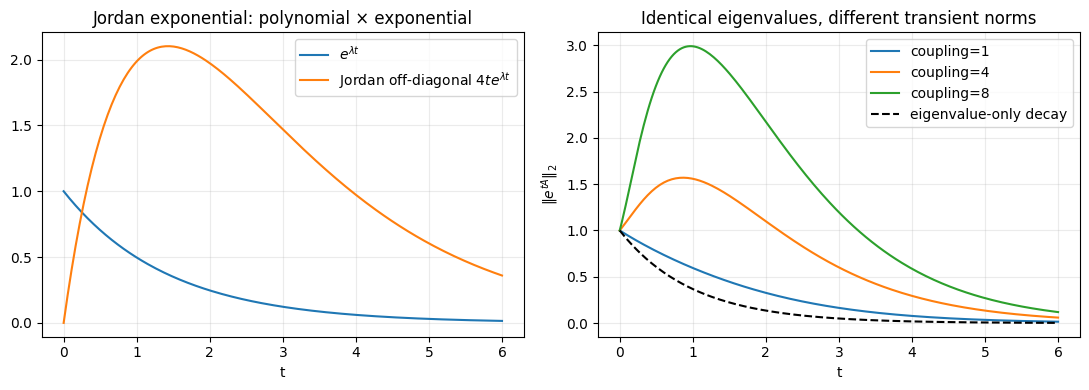

In [2]:
lam = -0.7
J = np.array([[lam, 4.0], [0., lam]])
N = J - lam*I(2)
exact_jordan = np.exp(lam)*(I(2)+N)
naive_eigenvalue_only = np.exp(lam)*I(2)
print('Jordan J =\n', J)
print('expm(J) =\n', expm(J))
print('Jordan formula error:', norm(expm(J)-exact_jordan))
print('Eigenvalues-only error:', norm(expm(J)-naive_eigenvalue_only))

t = np.linspace(0, 6, 220)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(t, np.exp(lam*t), label=r'$e^{\lambda t}$')
axes[0].plot(t, 4*t*np.exp(lam*t), label=r'Jordan off-diagonal $4te^{\lambda t}$')
axes[0].set(title='Jordan exponential: polynomial × exponential', xlabel='t'); axes[0].legend()
for v in [1, 4, 8]:
    A = np.array([[-1., v], [0., -1.]])
    axes[1].plot(t, [norm(expm(tt*A), 2) for tt in t], label=f'coupling={v}')
axes[1].plot(t, np.exp(-t), 'k--', label='eigenvalue-only decay')
axes[1].set(title='Identical eigenvalues, different transient norms', xlabel='t', ylabel=r'$\|e^{tA}\|_2$'); axes[1].legend()
plt.tight_layout(); plt.show()
assert norm(expm(J)-exact_jordan) < 1e-12

## Demo 2 — Exponential as the transition operator

$$\dot x=Ax,\quad x(t)=e^{tA}x(0).$$
A **nonnormal** stable matrix may have large transient growth even when all eigenvalues have negative real parts. Compare symmetric stable and upper-triangular stable systems.

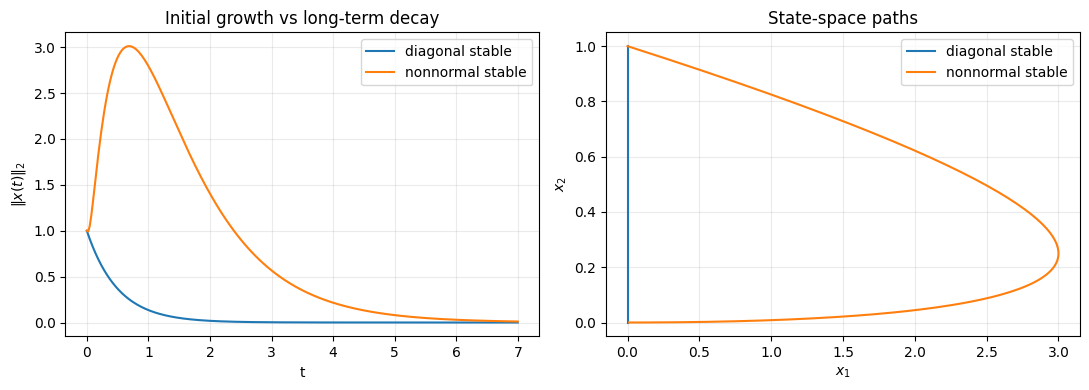

Eigenvalues, nonnormal: [-1. -2.]
Peak state norm: 3.010393189332158


In [3]:
A_normal = np.diag([-1., -2.])
A_nonnormal = np.array([[-1., 12.], [0., -2.]])
t = np.linspace(0, 7, 300)
x0 = np.array([0., 1.])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for A, label in [(A_normal,'diagonal stable'), (A_nonnormal,'nonnormal stable')]:
    trajectories = np.array([expm(ti*A) @ x0 for ti in t])
    axes[0].plot(t, np.linalg.norm(trajectories, axis=1), label=label)
    axes[1].plot(trajectories[:,0], trajectories[:,1], label=label)
axes[0].set(xlabel='t', ylabel=r'$\|x(t)\|_2$', title='Initial growth vs long-term decay'); axes[0].legend()
axes[1].set(xlabel=r'$x_1$', ylabel=r'$x_2$', title='State-space paths'); axes[1].legend()
plt.tight_layout(); plt.show()
print('Eigenvalues, nonnormal:', np.linalg.eigvals(A_nonnormal))
print('Peak state norm:', max(norm(expm(ti*A_nonnormal)@x0) for ti in t))

## Demo 3 — Noncommutativity and the Baker–Campbell–Hausdorff (BCH) correction

Generally $e^{A+B}\ne e^Ae^B$. Near zero,
$$\log(e^Ae^B)\approx A+B+\tfrac12[A,B],\qquad [A,B]=AB-BA.$$
Scale two noncommuting matrices by a small parameter $\varepsilon$ and compare errors with and without the leading commutator correction.

Commutator =
 [[ 0.2 -0.5]
 [-0.5 -0.2]]


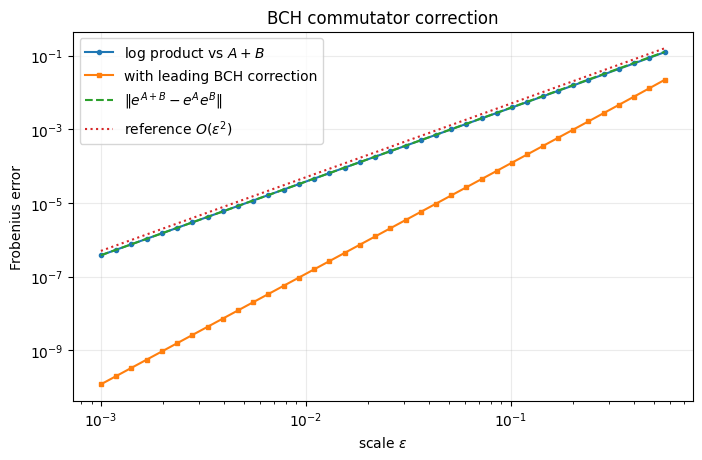

Smallest-epsilon improvement: 3193.47987054606


In [4]:
A0 = np.array([[0., 1.], [-1., 0.]])
B0 = np.array([[0.4, 0.2], [0., -0.1]])
print('Commutator =\n', A0@B0-B0@A0)
eps = np.logspace(-3, -0.25, 38)
errs_no = []; errs_bch = []; exp_split_err = []
for h in eps:
    A, B = h*A0, h*B0
    target = logm(expm(A)@expm(B))
    errs_no.append(norm(target - (A+B)))
    errs_bch.append(norm(target - (A+B+0.5*(A@B-B@A))))
    exp_split_err.append(norm(expm(A+B)-expm(A)@expm(B)))
plt.loglog(eps, errs_no, 'o-', ms=3, label=r'log product vs $A+B$')
plt.loglog(eps, errs_bch, 's-', ms=3, label='with leading BCH correction')
plt.loglog(eps, exp_split_err, '--', label=r'$\|e^{A+B}-e^Ae^B\|$')
plt.loglog(eps, .5*eps**2, ':', label=r'reference $O(\varepsilon^2)$')
plt.xlabel(r'scale $\varepsilon$'); plt.ylabel('Frobenius error'); plt.title('BCH commutator correction'); plt.legend(); plt.show()
print('Smallest-epsilon improvement:', errs_no[0]/errs_bch[0])

## Demo 4 — Matrix exponential Fréchet derivative

The exact directional derivative is
$$ L_{\exp}(A,E)=\int_0^1 e^{(1-s)A}E e^{sA}\,ds. $$
Check **three ways**: SciPy's `expm_frechet`, numerical quadrature of the integral, and finite differences. The finite-difference error eventually increases due to cancellation.

Integral / SciPy error: 6.206335383118183e-16
Naive exp(A) E discrepancy: 0.8919857452464586


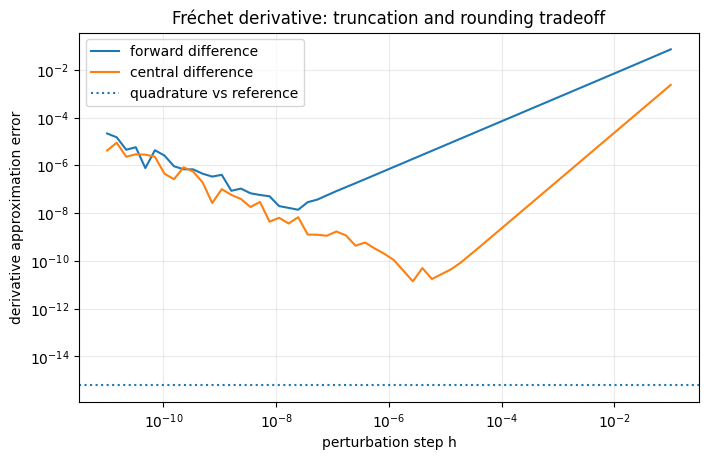

In [5]:
A = np.array([[0.2, 1.1], [-0.35, -0.4]])
E = np.array([[0., 1.], [1., 0.]])
L_ref = expm_frechet(A, E, compute_expm=False)
nodes, weights = leggauss(70)
s = (nodes+1)/2; w = weights/2
L_quad = sum(wj*expm((1-sj)*A)@E@expm(sj*A) for sj,wj in zip(s,w))
print('Integral / SciPy error:', norm(L_quad-L_ref))
print('Naive exp(A) E discrepancy:', norm(expm(A)@E-L_ref))
hs = np.logspace(-11,-1,60)
fd_forward = [norm((expm(A+h*E)-expm(A))/h-L_ref,'fro') for h in hs]
fd_central = [norm((expm(A+h*E)-expm(A-h*E))/(2*h)-L_ref,'fro') for h in hs]
plt.loglog(hs, fd_forward, label='forward difference')
plt.loglog(hs, fd_central, label='central difference')
plt.axhline(norm(L_quad-L_ref), ls=':', label='quadrature vs reference')
plt.xlabel('perturbation step h'); plt.ylabel('derivative approximation error')
plt.title('Fréchet derivative: truncation and rounding tradeoff'); plt.legend(); plt.show()
assert norm(L_quad-L_ref) < 1e-11

## Demo 5 — Conditioning and worst perturbation direction

For the Frobenius norm, represent $E\mapsto L_f(A,E)$ as a linear map on vectorized matrices. Its spectral norm is the **absolute condition number** $\|L_f(A)\|_{F\to F}$.

The relative condition number is $\kappa_f(A)=\|L_f(A)\|\,\|A\|_F/\|f(A)\|_F$. Here we demonstrate the exponential and numerically identify an approximately maximally amplifying perturbation.

Absolute condition number: 3.961245709065177
Relative condition number: 10.767782229013239
Worst direction (normalized):
 [[-0.31853 -0.08256]
 [-0.88896 -0.31853]]
Amplification in worst direction: 3.961245709065176
Amplification along identity: 1.8577001164164322


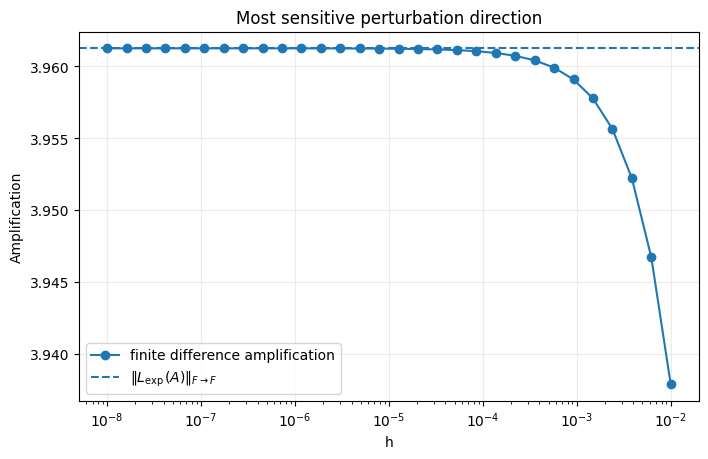

In [6]:
def frechet_operator_matrix(A, derivative_fn):
    n = A.shape[0]; K = np.zeros((n*n,n*n),dtype=complex)
    for j in range(n*n):
        E = np.zeros((n,n),dtype=complex)
        E = np.zeros((n,n),dtype=complex); E[j%n, j//n] = 1
        K[:,j] = derivative_fn(A,E).reshape(-1, order='F')
    return K

A = np.array([[-1., 7.], [0., -1.]])
K = frechet_operator_matrix(A, lambda M,E: expm_frechet(M,E,compute_expm=False))
U,svals,Vh = np.linalg.svd(K)
E_worst = Vh.conj().T[:,0].reshape(A.shape,order='F')
E_simple = I(2)/np.sqrt(2)
kappa = svals[0]*norm(A,'fro')/norm(expm(A),'fro')
print('Absolute condition number:', svals[0])
print('Relative condition number:', kappa)
print('Worst direction (normalized):\n', np.real_if_close(E_worst))
print('Amplification in worst direction:', norm(expm_frechet(A,E_worst,compute_expm=False))/norm(E_worst))
print('Amplification along identity:', norm(expm_frechet(A,E_simple,compute_expm=False))/norm(E_simple))
hs = np.logspace(-8,-2,30)
obs = [norm(expm(A+h*E_worst)-expm(A),'fro')/h for h in hs]
plt.semilogx(hs,obs,'o-',label='finite difference amplification')
plt.axhline(svals[0],ls='--',label=r'$\|L_{\exp}(A)\|_{F\to F}$')
plt.xlabel('h'); plt.ylabel('Amplification');plt.title('Most sensitive perturbation direction');plt.legend();plt.show()

## Demo 6 — Padé scaling-and-squaring versus truncated Taylor

The core identity is $e^A=(e^{A/2^s})^{2^s}$. A diagonal Padé approximant $r_m(z)=p_m(z)/p_m(-z)$ approximates the **scaled** exponential. We implement a small educational version, choosing $m=6$ and an illustrative scaling threshold; production implementations select degree and scaling using sophisticated backward-error bounds.

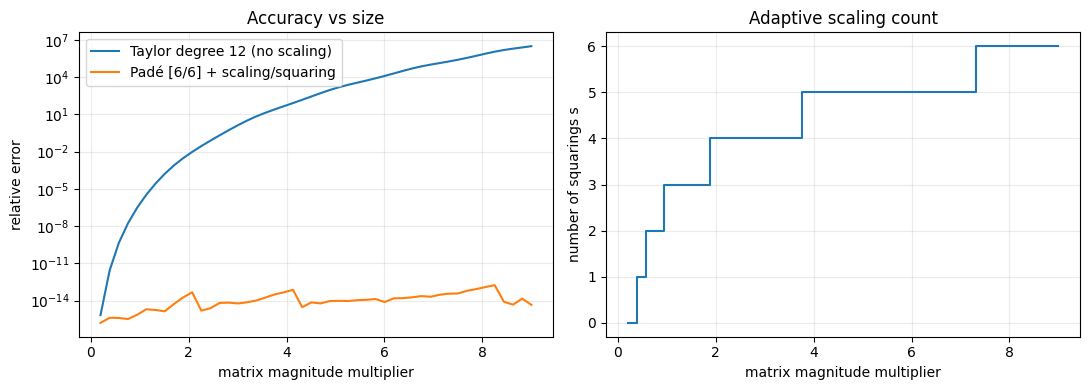

Sample computed exp(A) residual: 5.5171777421893675e-14


In [7]:
from math import factorial as fac

def pade_exp(A, m=6):
    n=A.shape[0]; P=np.zeros_like(A,dtype=complex); Q=np.zeros_like(A,dtype=complex)
    power=np.eye(n,dtype=complex)
    for j in range(m+1):
        bj=fac(2*m-j)*fac(m)/(fac(2*m)*fac(m-j)*fac(j))
        P+=bj*power; Q+=bj*((-1)**j)*power
        power=power@A
    return np.linalg.solve(Q,P)

def expm_scaling_squaring_demo(A,m=6,threshold=.7):
    s=max(0,int(np.ceil(np.log2(max(norm(A,1),1e-15)/threshold))))
    X=pade_exp(A/2**s,m)
    for _ in range(s): X=X@X
    return np.real_if_close(X),s

def taylor_exp(A,k):
    X=np.eye(A.shape[0],dtype=complex); power=X.copy()
    for j in range(1,k+1):
        power=power@A/j; X+=power
    return X

A0=np.array([[-0.4,3.],[-1.2,0.1]])
scales=np.linspace(.2,9.,48)
err_t=[];err_pade=[];scount=[]
for alpha in scales:
    A=alpha*A0;truth=expm(A)
    P,s=expm_scaling_squaring_demo(A)
    err_pade.append(relative_error(P,truth))
    err_t.append(relative_error(taylor_exp(A,12),truth))
    scount.append(s)
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].semilogy(scales,err_t,label='Taylor degree 12 (no scaling)')
axs[0].semilogy(scales,err_pade,label='Padé [6/6] + scaling/squaring')
axs[0].set(xlabel='matrix magnitude multiplier', ylabel='relative error',title='Accuracy vs size');axs[0].legend()
axs[1].step(scales,scount,where='post');axs[1].set(xlabel='matrix magnitude multiplier',ylabel='number of squarings s',title='Adaptive scaling count')
plt.tight_layout();plt.show()
print('Sample computed exp(A) residual:', relative_error(expm_scaling_squaring_demo(4*A0)[0],expm(4*A0)))

## Demo 7 — Principal logarithm and branch wrapping

For a rotation generator $J=\left[\begin{smallmatrix}0&-1\\1&0\end{smallmatrix}\right]$, $R(\theta)=e^{\theta J}$. Its principal logarithm returns angles in $(-\pi,\pi)$, not necessarily the original angle. At $\theta=\pm\pi$ eigenvalues lie on the branch cut: avoid those points.

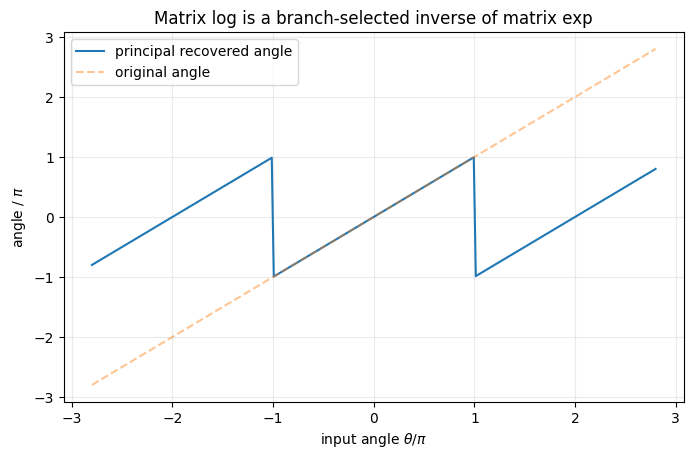

Max reconstruction error away from cut: 3.140430234731892e-15
log(R(1.6π)) coefficient: -1.2566370614359177
Expectation: -0.4π ≈ -1.2566370614359172


In [8]:
J=np.array([[0.,-1.],[1.,0.]])
angles=np.linspace(-2.8*np.pi,2.8*np.pi,280)
angles=angles[np.abs(np.abs((angles+np.pi)%(2*np.pi)-np.pi)-np.pi)>0.015]
recovered=[]; recon_errors=[]
for theta in angles:
    R=expm(theta*J)
    X=logm(R)
    recovered.append(np.real(np.trace(J.T@X)/2))
    recon_errors.append(relative_error(expm(X),R))
plt.plot(angles/np.pi,np.array(recovered)/np.pi,label='principal recovered angle')
plt.plot(angles/np.pi,angles/np.pi,'--',alpha=.45,label='original angle')
plt.xlabel(r'input angle $\theta/\pi$');plt.ylabel(r'angle / $\pi$')
plt.title('Matrix log is a branch-selected inverse of matrix exp')
plt.legend();plt.show()
print('Max reconstruction error away from cut:',max(recon_errors))
print('log(R(1.6π)) coefficient:',np.real(np.trace(J.T@logm(expm(1.6*np.pi*J)))/2))
print('Expectation: -0.4π ≈',-0.4*np.pi)

## Demo 8 — Matrix logarithm series and resolvent quadrature

Near identity, $\log(I+X)=\sum_{k=1}^{\infty}(-1)^{k+1}X^k/k$ when $\rho(X)<1$.

The Cayley-transformed Gregory series uses $Z=(A-I)(A+I)^{-1}$:
$$\log A=2\sum_{k\ge 0}\frac{Z^{2k+1}}{2k+1}.$$

For a matrix with spectrum away from $(-\infty,0]$,
$$\log A=\int_0^1(A-I)[I+t(A-I)]^{-1}dt.$$
We approximate this integral with Gauss–Legendre quadrature, illustrating why rational approximation and quadrature are connected.

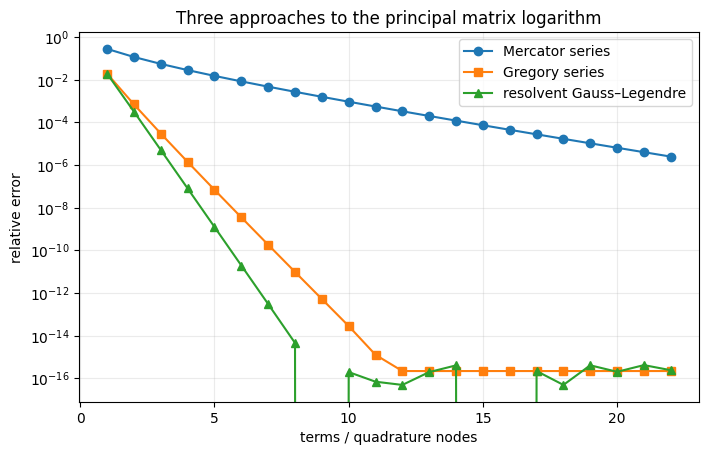

spectral radius(A-I): 0.6499999999999999
quadrature (12 nodes) rel. error: 4.905365933184066e-17


In [9]:
A = np.array([[1.65, .25], [0., .85]])
X=A-I(2); truth=logm(A)
Z=np.linalg.solve(A+I(2), A-I(2))
def mercator(X,terms):
    total=np.zeros_like(X,dtype=complex); P=I(X.shape[0]).astype(complex)
    for k in range(1,terms+1):
        P=P@X; total+=(-1)**(k+1)*P/k
    return total
def gregory(Z,terms):
    total=np.zeros_like(Z,dtype=float); P=Z.copy(); Z2=Z@Z
    for k in range(terms):
        total+=2*P/(2*k+1);P=P@Z2
    return total
def log_quad(A,m):
    nodes,weights=leggauss(m);ts=(nodes+1)/2;ws=weights/2
    X=A-I(A.shape[0]); out=np.zeros_like(A,dtype=float)
    for t,w in zip(ts,ws): out+=w*np.linalg.solve(I(A.shape[0])+t*X,X)
    return out
ns=np.arange(1,23)
plt.semilogy(ns,[relative_error(mercator(X,m),truth) for m in ns],'o-',label='Mercator series')
plt.semilogy(ns,[relative_error(gregory(Z,m),truth) for m in ns],'s-',label='Gregory series')
plt.semilogy(ns,[relative_error(log_quad(A,m),truth) for m in ns],'^-',label='resolvent Gauss–Legendre')
plt.xlabel('terms / quadrature nodes');plt.ylabel('relative error')
plt.title('Three approaches to the principal matrix logarithm');plt.legend();plt.show()
print('spectral radius(A-I):',max(abs(np.linalg.eigvals(X))))
print('quadrature (12 nodes) rel. error:',relative_error(log_quad(A,12),truth))

## Demo 9 — Inverse scaling and squaring for matrix log

Since $\log A=2^s\log(A^{1/2^s})$ on the principal branch, repeated matrix square roots reduce the argument toward $I$. We then apply a low-order local Mercator approximation. This is intentionally simple to expose the principle; high-quality log algorithms employ Padé approximants, Schur methods, and careful numerical safeguards.

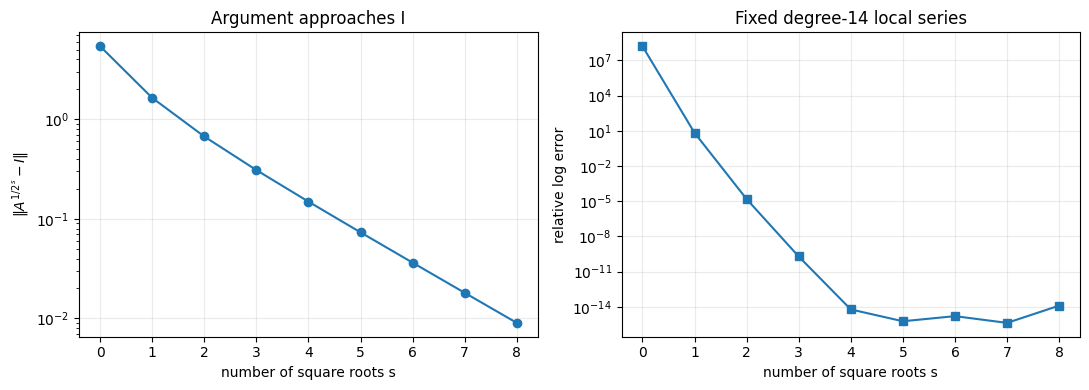

error at s=0: 164937855.98634344 ; at s=8: 1.2724528484356437e-14


In [10]:
A=np.array([[6.,2.], [0.,0.35]])
ref=logm(A)
steps=np.arange(0,9)
errors=[]; distances=[]
for s in steps:
    B=A.copy().astype(complex)
    for j in range(s): B=sqrtm(B).astype(complex)
    distances.append(norm(B-I(2)))
    errors.append(relative_error((2**s)*mercator(B-I(2),14) if np.max(np.abs(np.imag(B))) < 1e-12 else (2**s)*sum(((-1)**(k+1)) * np.linalg.matrix_power(B-I(2),k)/k for k in range(1,15)),ref))
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].semilogy(steps, distances,'o-');ax[0].set(xlabel='number of square roots s',ylabel=r'$\|A^{1/2^s}-I\|$',title='Argument approaches I')
ax[1].semilogy(steps, errors,'s-');ax[1].set(xlabel='number of square roots s',ylabel='relative log error',title='Fixed degree-14 local series')
plt.tight_layout();plt.show()
print('error at s=0:', errors[0],'; at s=8:',errors[-1])

## Demo 10 — Logarithm Fréchet derivative and the inverse-chain identity

Let $X=\log A$. Then
$$L_{\exp}(X,L_{\log}(A,E))=E.$$

The logarithm directional derivative has the integral form
$$L_{\log}(A,E)=\int_0^1[I+t(A-I)]^{-1}E[I+t(A-I)]^{-1}dt.$$
We verify both numerically for an upper triangular positive-eigenvalue matrix.

In [11]:
A=np.array([[2.0,0.65],[0.,1.2]])
E=np.array([[0.2,-0.7],[0.4,0.1]])
def log_frechet_quad(A,E,m=80):
    t,w=leggauss(m);t=(t+1)/2;w=w/2
    X=A-I(A.shape[0]);out=np.zeros_like(A,dtype=complex)
    for tj,wj in zip(t,w):
        R=np.linalg.inv(I(A.shape[0])+tj*X)
        out+=wj*(R@E@R)
    return out
Llog=log_frechet_quad(A,E)
chain=expm_frechet(logm(A),Llog,compute_expm=False)
print('Inverse-chain relative residual:',relative_error(chain,E))
print('Log derivative vs naive A^-1 E:',norm(Llog-np.linalg.solve(A,E)))
for h in [1e-2,1e-4,1e-6]:
    finite=(logm(A+h*E)-logm(A-h*E))/(2*h)
    print(f'h={h:.0e}: central-difference residual={relative_error(finite,Llog):.3e}')
assert relative_error(chain,E) < 1e-10

Inverse-chain relative residual: 5.362031587114109e-16
Log derivative vs naive A^-1 E: 0.1510162200822131
h=1e-02: central-difference residual=4.167e-06
h=1e-04: central-difference residual=4.154e-10
h=1e-06: central-difference residual=7.864e-11


## Demo 11 — Matrix cosine, sine and Euler's formula

$$\cos A=\frac{e^{iA}+e^{-iA}}2,\qquad \sin A=\frac{e^{iA}-e^{-iA}}{2i}.$$
For any matrix, both $\cos A$ and $\sin A$ are functions of the same $A$, so they commute and satisfy $\cos^2A+\sin^2A=I$. Compare with independently computed SciPy results. For a real symmetric matrix, its eigenmodes follow scalar sine and cosine curves.

Euler cosine discrepancy: 0.0
Euler sine discrepancy: 0.0
Pythagorean matrix residual: 2.220446049250313e-16
Commutator norm: 5.551115123125783e-17


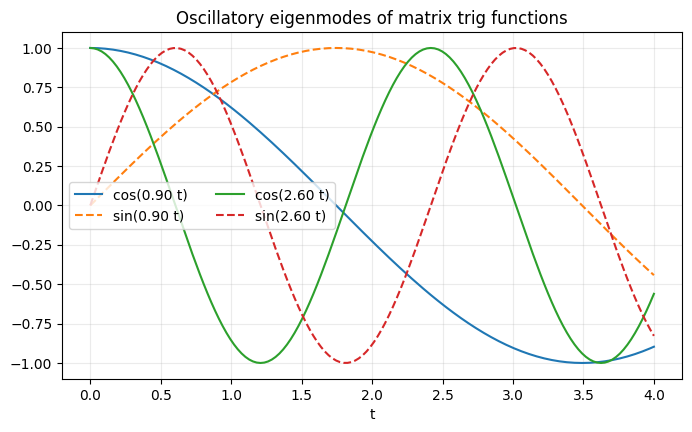

In [12]:
A=np.array([[0.6, 1.3],[-.25,0.2]])
C=cosm(A); S=sinm(A)
Ce=(expm(1j*A)+expm(-1j*A))/2
Se=(expm(1j*A)-expm(-1j*A))/(2j)
print('Euler cosine discrepancy:',norm(C-Ce))
print('Euler sine discrepancy:',norm(S-Se))
print('Pythagorean matrix residual:',norm(C@C+S@S-I(2)))
print('Commutator norm:',norm(C@S-S@C))
H=np.array([[1.,.4],[.4,2.5]])
t=np.linspace(0,4,150)
fig,ax=plt.subplots(figsize=(8,4.5))
for i,lam in enumerate(np.linalg.eigvalsh(H)):
    ax.plot(t,np.cos(lam*t),label=f'cos({lam:.2f} t)')
    ax.plot(t,np.sin(lam*t),'--',label=f'sin({lam:.2f} t)')
ax.set(title='Oscillatory eigenmodes of matrix trig functions',xlabel='t');ax.legend(ncol=2);plt.show()

## Demo 12 — Double-angle reconstruction of cosine and sine

The exact identities are
$$C_{k+1}=2C_k^2-I,\qquad S_{k+1}=2S_kC_k.$$
We initialize $C_0=\cos(A/2^s)$ and $S_0=\sin(A/2^s)$ using truncated Taylor series, then reconstruct. Increasing the scaling count reduces the initial series error, but many double-angle steps can amplify roundoff and cancellation.

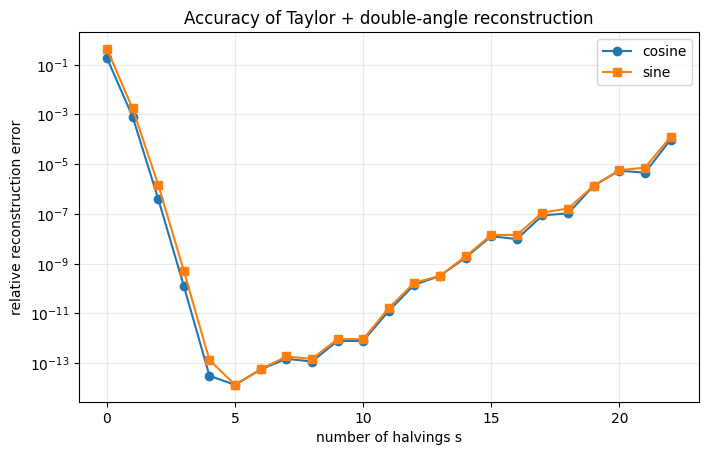

At s=8: cos error= 1.148329864084377e-13 sin error= 1.4661866817299752e-13


In [13]:
def trig_taylor(B,degree=12):
    n=B.shape[0];C=np.eye(n,dtype=complex);S=np.zeros((n,n),dtype=complex)
    power=np.eye(n,dtype=complex)
    for k in range(1,degree+1):
        power=power@B/k
        if k%2==0: C+=(-1)**(k//2)*power
        else: S+=(-1)**((k-1)//2)*power
    return C,S

def double_angle_demo(A,s,degree=12):
    C,S=trig_taylor(A/2**s,degree)
    for _ in range(s):
        Snew=2*S@C
        Cnew=2*C@C-I(A.shape[0])
        C,S=Cnew,Snew
    return C,S
A=np.array([[1.2,1.5],[-0.8,0.2]])*7
svalues=np.arange(0,23)
cerr=[];serr=[]
for s in svalues:
    C,S=double_angle_demo(A,int(s),12)
    cerr.append(relative_error(C,cosm(A)))
    serr.append(relative_error(S,sinm(A)))
plt.semilogy(svalues,cerr,'o-',label='cosine')
plt.semilogy(svalues,serr,'s-',label='sine')
plt.xlabel('number of halvings s');plt.ylabel('relative reconstruction error')
plt.title('Accuracy of Taylor + double-angle reconstruction');plt.legend();plt.show()
C,S=double_angle_demo(A,8,12)
print('At s=8: cos error=',relative_error(C,cosm(A)),'sin error=',relative_error(S,sinm(A)))

## Demo 13 — Coupled oscillators: a second-order system

For $\ddot x+Kx=0$ with $K$ symmetric positive definite and $\Omega=K^{1/2}$,
$$x(t)=\cos(t\Omega)x_0+\Omega^{-1}\sin(t\Omega)v_0.$$
The equivalent first-order generator is $\mathcal A=\left[\begin{smallmatrix}0&I\\-K&0\end{smallmatrix}\right]$. This demo compares the closed-form trigonometric solution with $e^{t\mathcal A}$ and plots conserved energy
$$\mathcal E(t)=\tfrac12v^Tv+\tfrac12x^TKx.$$

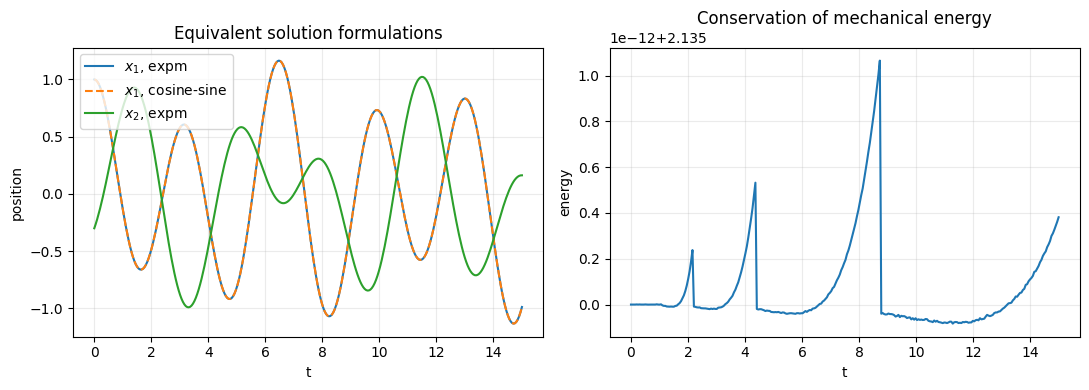

Max state discrepancy: 1.766027057617825e-13
Max energy deviation: 1.0658141036401503e-12


In [14]:
K=np.array([[3.,-1.],[-1.,2.]])
Om=np.real_if_close(sqrtm(K))
G=np.block([[np.zeros((2,2)),I(2)],[-K,np.zeros((2,2))]])
x0=np.array([1.,-.3]);v0=np.array([0.,.7]);z0=np.r_[x0,v0]
t=np.linspace(0,15,300)
z=np.array([expm(tt*G)@z0 for tt in t])
x_closed=np.array([cosm(tt*Om)@x0 + np.linalg.solve(Om,sinm(tt*Om)@v0) for tt in t])
energy=.5*np.einsum('ij,ij->i',z[:,2:],z[:,2:])+.5*np.einsum('ij,ij->i',z[:,:2]@K,z[:,:2])
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].plot(t,z[:,0],label=r'$x_1$, expm');axs[0].plot(t,x_closed[:,0],'--',label=r'$x_1$, cosine-sine')
axs[0].plot(t,z[:,1],label=r'$x_2$, expm');axs[0].set(xlabel='t',ylabel='position',title='Equivalent solution formulations');axs[0].legend()
axs[1].plot(t,energy);axs[1].set(xlabel='t',ylabel='energy',title='Conservation of mechanical energy')
plt.tight_layout();plt.show()
print('Max state discrepancy:',np.max(np.linalg.norm(z[:,:2]-x_closed,axis=1)))
print('Max energy deviation:',np.max(np.abs(energy-energy[0])))
assert np.max(np.linalg.norm(z[:,:2]-x_closed,axis=1)) < 1e-10

## Demo 14 — Integrated example: $SO(2)$ group exponential and principal logarithm

Let $J=\left[\begin{smallmatrix}0&-1\\1&0\end{smallmatrix}\right]$. Then
$$R(\theta)=e^{\theta J}=\begin{bmatrix}\cos\theta&-\sin\theta\\\sin\theta&\cos\theta\end{bmatrix},$$
and $\log R(\theta)=\theta J$ only when $-\pi<\theta<\pi$ (principal branch). We visualize the rotation of a unit vector and verify orthogonality, determinant, and logarithm recovery.

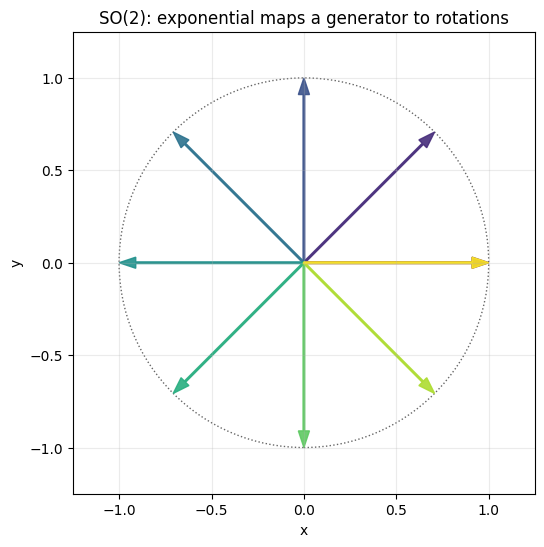

theta=0.5236 | recovered principal=0.5236 | orthogonality=2.10e-17 | det=1.000000
theta=1.5708 | recovered principal=1.5708 | orthogonality=0.00e+00 | det=1.000000
theta=4.3982 | recovered principal=-1.8850 | orthogonality=8.64e-15 | det=1.000000


In [15]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
J=np.array([[0.,-1.],[1.,0.]])
ths=np.linspace(0,2*np.pi,9)
fig,ax=plt.subplots(figsize=(6,6))
ax.add_patch(plt.Circle((0,0),1,fill=False,linestyle=':',alpha=.6))
colors=plt.cm.viridis(np.linspace(0,1,len(ths)))
for th,c in zip(ths,colors):
    r=expm(th*J)@np.array([1.,0.])
    ax.arrow(0,0,r[0],r[1],width=.009,head_width=.06,length_includes_head=True,color=c,alpha=.9)
ax.set(xlim=(-1.25,1.25),ylim=(-1.25,1.25),xlabel='x',ylabel='y',title='SO(2): exponential maps a generator to rotations')
ax.set_aspect('equal');plt.show()
for theta in [np.pi/6, np.pi/2, 1.4*np.pi]:
    R=expm(theta*J)
    alpha=float(np.real(np.trace(J.T@logm(R))/2))
    print(f'theta={theta:.4f} | recovered principal={alpha:.4f} | orthogonality={norm(R.T@R-I(2)):.2e} | det={np.linalg.det(R):.6f}')

## Additional experiment — Compare direct computation with spectral diagonalization

For normal matrices, an orthonormal eigenbasis is well conditioned. For strongly nonnormal diagonalizable matrices, eigenvectors can be ill-conditioned, and evaluating $V f(\Lambda)V^{-1}$ numerically may lose accuracy. This also helps explain Higham's emphasis on Schur-based algorithms.

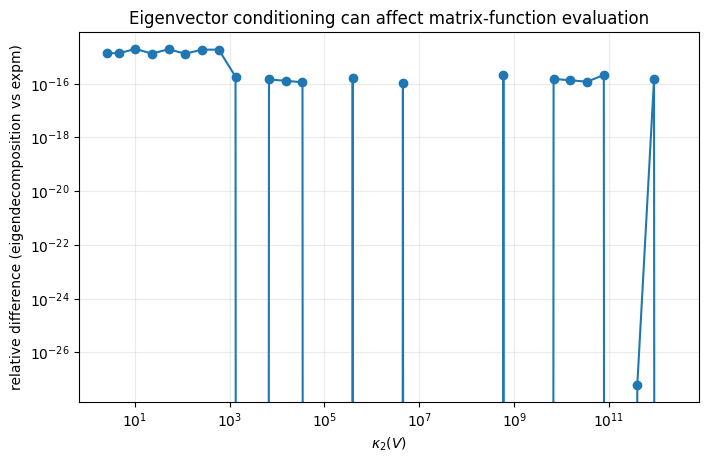

Note: comparisons against SciPy for extremely nonnormal matrices can also become challenging.


In [16]:
eigenvalues=np.array([-1.,-2.])
conds=np.logspace(0,12,35)
errors=[]; actual_cond=[]
for k in conds:
    V=np.array([[1.,1.],[0.,1./k]])
    A=V@np.diag(eigenvalues)@np.linalg.inv(V)
    Fdiag=V@np.diag(np.exp(eigenvalues))@np.linalg.inv(V)
    errors.append(relative_error(Fdiag,expm(A)))
    actual_cond.append(np.linalg.cond(V))
plt.loglog(actual_cond,errors,'o-')
plt.xlabel(r'$\kappa_2(V)$');plt.ylabel('relative difference (eigendecomposition vs expm)')
plt.title('Eigenvector conditioning can affect matrix-function evaluation');plt.show()
print('Note: comparisons against SciPy for extremely nonnormal matrices can also become challenging.')

## Summary — the methodological master framework

| Question | Mathematical formulation | Numerical lesson |
|---|---|---|
| **What is $f(A)$?** | Spectral/Jordan and analytic calculus | Defective matrices need derivatives of $f$ |
| **What does $e^{tA}$ mean?** | $\dot x=Ax\Rightarrow x(t)=e^{tA}x_0$ | Stable eigenvalues do not preclude transients |
| **Why does order matter?** | $[A,B]=AB-BA$ and BCH | Composition is generally noncommutative |
| **How does $f(A)$ change?** | $f(A+E)=f(A)+L_f(A,E)+o(\|E\|)$ | Direction matters; use Fréchet derivatives |
| **How to compute exp?** | Scale → Padé → square | Control approximation and backward error |
| **How to invert exp?** | Principal $\log A$ | Spectral branches matter |
| **How to compute log?** | Repeated square roots → Padé/quadrature → rescale | Bring argument close to identity |
| **How to compute trig?** | Euler plus double-angle identities | Reuse powers and reconstruct carefully |
| **How to model oscillations?** | $\ddot x+Kx=0$ | Matrix sine/cosine propagate mechanical states |

**Suggested extensions:** (1) derive the Fréchet derivative using automatic differentiation; (2) inspect logarithms near the negative real-axis branch cut; (3) compare custom Padé methods on larger nonnormal matrices; (4) extend $SO(2)$ to $SO(3)$ and $SE(3)$ using exponential coordinates.

**Reference:** N. J. Higham, *Functions of Matrices: Theory and Computation*, SIAM, 2008, Chapters 10–12. The numerical demonstrations and teaching implementations in this notebook are newly constructed to explain the methods, not reproduced figures or benchmark data from the book.